# Semana 4 — Treinamento e integração de um modelo surrogate
### Amostragem LHS, sintonia do SMA por instância e regressão com MLP

**Problema:** Permutation Flow Shop Scheduling (PFS) · **Objetivo:** minimizar Total Tardiness.

O estudo compreende duas instâncias com dimensões distintas. Para cada uma delas, a configuração do Slime Mould Algorithm (SMA) é ajustada pelo Optuna. A amostragem combina permutações obtidas por Latin Hypercube Sampling (LHS) e soluções avaliadas em execuções independentes do SMA. Uma rede MLP aprende a aproximar o valor da função objetivo. Ao final, o modelo é incorporado a uma versão assistida do solver e comparado à avaliação exata.

A interpretação dos arquivos e a avaliação PFS permanecem as mesmas das etapas anteriores. A linha referente ao número de fábricas é ignorada nesta formulação; **não é realizada distribuição de trabalhos entre fábricas**.

**Critérios de avaliação:** MSE, RMSE, R² e MAE da regressão; correlação de Spearman; tempo de inferência; avaliações exatas; Total Tardiness final e tempo total de otimização. Os resultados são gerados pela execução das células, sem valores previamente atribuídos.

**Método:** PFS com random keys, função de avaliação exata e predição supervisionada de fitness.


## 1. Protocolo experimental

| Fase | Procedimento | Controle metodológico |
|---|---|---|
| A | Sintonia SMA+Optuna por instância | Otimização apenas na instância correspondente, com sementes fixas para comparação das trials |
| B | Amostragem LHS | Conversão de Random Keys em permutações por `argsort` |
| C | Coleta durante o SMA tunado | Sementes diferentes das usadas na sintonia; registrar fitness **real** de todos os candidatos avaliados |
| D | Construção do dataset | Remoção de permutações duplicadas e divisão treino/validação/teste antes do ajuste dos escaladores |
| E | Treino MLP | Uma rede independente por instância; early stopping e normalização ajustada só no treino |
| F | Integração ao SMA | Rede classifica candidatos; o fitness exato confirma os selecionados |
| G | Comparação | Mesmo limite de avaliações exatas por execução; custos de coleta e treino apresentados separadamente |

**Observação:** a sintonia é uma preparação específica de cada instância, não uma avaliação da capacidade de generalização entre instâncias. O conjunto de teste da regressão contém permutações não vistas; a instância, contudo, continua sendo a mesma.

In [1]:
import sys, subprocess, importlib.util, time, json, zipfile, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.stats import qmc, spearmanr
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.model_selection import train_test_split

for pacote in ['optuna','torch']:
    if importlib.util.find_spec(pacote) is None:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', pacote])
import optuna
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

# False executa uma verificação rápida da integridade do pipeline.
EXECUCAO_COMPLETA = True
SEMENTE_GLOBAL = 2026
np.random.seed(SEMENTE_GLOBAL)
torch.manual_seed(SEMENTE_GLOBAL)
torch.set_num_threads(2)
optuna.logging.set_verbosity(optuna.logging.WARNING)
plt.rcParams.update({'figure.dpi':115, 'font.size':10, 'axes.grid':True, 'grid.alpha':.18})
OUT = Path('/kaggle/working/semana4_surrogate' if Path('/kaggle/working').exists() else '/mnt/data/semana4_surrogate')
OUT.mkdir(parents=True, exist_ok=True)
CONFIG = {
    'trials': 50 if EXECUCAO_COMPLETA else 2,
    'seeds_optuna': [107, 211] if EXECUCAO_COMPLETA else [107],
    'cfo_optuna': 2000 if EXECUCAO_COMPLETA else 90,
    'samples': {'Large/Ta001_2.txt': 10000 if EXECUCAO_COMPLETA else 240,
                'Large/Ta041_3.txt': 20000 if EXECUCAO_COMPLETA else 240},
    'frac_sma': .30,
    'cfo_coleta': 3000 if EXECUCAO_COMPLETA else 120,
    'max_rodadas_coleta': 25 if EXECUCAO_COMPLETA else 3,
    'epochs': 150 if EXECUCAO_COMPLETA else 3,
    'patience': 18 if EXECUCAO_COMPLETA else 2,
    'batch_size': 256,
    'cfo_comparacao': 3000 if EXECUCAO_COMPLETA else 150,
    'seeds_comparacao': [401, 503, 607, 709, 811] if EXECUCAO_COMPLETA else [401],
    'frac_selecao': .40
}
print('Modo:', 'EXPERIMENTO COMPLETO' if EXECUCAO_COMPLETA else 'VERIFICAÇÃO')
display(pd.DataFrame([{'configuracao':k,'valor':str(v)} for k,v in CONFIG.items()]))
print('Saída:', OUT)

Modo: EXPERIMENTO COMPLETO


,configuracao,valor
0,trials,50
1,seeds_optuna,"[107, 211]"
2,cfo_optuna,2000
3,samples,"{'Large/Ta001_2.txt': 10000, 'Large/Ta041_3.tx..."
4,frac_sma,0.3
5,cfo_coleta,3000
6,max_rodadas_coleta,25
7,epochs,150
8,patience,18
9,batch_size,256


Saída: /kaggle/working/semana4_surrogate


## 2. Leitura das instâncias e função objetivo

A leitura segue o formato TXT do conjunto `DPFSP_DD`: primeira linha com trabalhos e máquinas, segunda linha ignorada, linhas de pares máquina–tempo e seção `Duedate`. A função objetivo corresponde ao **atraso total**:

\[TT(\pi)=\sum_{j=1}^{n}\max(0,C_j(\pi)-d_j).\]

Todos os rótulos supervisionados são calculados pelo mesmo avaliador exato. Arquivos ausentes ou malformados provocam erro em vez de serem substituídos por dados sintéticos.

In [2]:
BASES = [Path('/kaggle/input/datasets/caiomoreiraban/dpfsp-dd/DPFSP_DD'),
         Path('/kaggle/input/dpfsp-dd/DPFSP_DD'), Path('/mnt/data/DPFSP_DD')]
DATASET_DIR = next((p for p in BASES if p.is_dir() and any(p.rglob('*.txt'))), None)
if DATASET_DIR is None and Path('/mnt/data/DPFSP_DD.zip').is_file():
    with zipfile.ZipFile('/mnt/data/DPFSP_DD.zip') as z:
        z.extractall('/mnt/data')
    DATASET_DIR = Path('/mnt/data/DPFSP_DD')
if DATASET_DIR is None and Path('/kaggle/input').exists():
    for p in Path('/kaggle/input').rglob('*.txt'):
        if 'DPFSP_DD' in p.parts:
            DATASET_DIR = next(a for a in p.parents if a.name=='DPFSP_DD'); break
if DATASET_DIR is None:
    raise FileNotFoundError('Adicione DPFSP_DD à seção Input do Kaggle.')

class FlowShopEngine:
    def __init__(self,n_jobs,n_machines,proc_times,due_dates):
        self.n_jobs=n_jobs; self.n_machines=n_machines
        self.proc_times=np.asarray(proc_times,dtype=np.int32)
        self.due_dates=np.asarray(due_dates,dtype=np.int32)
        self.cfo_count=0

    @staticmethod
    def carregar_instancia_txt(caminho):
        with open(caminho, encoding='utf-8') as f:
            linhas=[linha.strip() for linha in f if linha.strip()]
        n,m=map(int,linhas[0].split()); mat=np.zeros((n,m),dtype=np.int32)
        for j in range(n):
            pares=list(map(int,linhas[j+2].split()))
            if len(pares)!=2*m: raise ValueError(f'Linha inválida do trabalho {j}')
            maquinas=pares[::2]; tempos=pares[1::2]
            if sorted(maquinas)!=list(range(m)): raise ValueError('Índices de máquinas inválidos')
            mat[j,maquinas]=tempos
        idx=next((i for i,l in enumerate(linhas) if l.lower()=='duedate'),None)
        if idx is None: raise ValueError('Seção Duedate ausente')
        due=np.asarray([int(v) for v in linhas[idx+1:idx+1+n]],dtype=np.int32)
        if len(due)!=n: raise ValueError('Prazos incompletos')
        return n,m,mat,due

    def bucket_sort_decode(self,keys):
        return np.argsort(np.asarray(keys)[:self.n_jobs],kind='stable')

    def evaluate_with_permutation(self,permutation,objective='Tardiness'):
        self.cfo_count+=1
        seq=np.asarray(permutation,dtype=int)
        if len(seq)!=self.n_jobs or not np.array_equal(np.sort(seq),np.arange(self.n_jobs)):
            raise ValueError('Permutação inválida')
        term=np.zeros((self.n_machines,self.n_jobs),dtype=float)
        for maquina in range(self.n_machines):
            disponivel=0.
            for j in seq:
                disponivel=max(disponivel,term[maquina-1,j] if maquina>0 else 0.)+self.proc_times[j,maquina]
                term[maquina,j]=disponivel
        if objective=='Makespan': return float(term[-1].max())
        if objective=='Tardiness': return float(np.maximum(term[-1]-self.due_dates,0).sum())
        raise ValueError('Objetivo inválido')

    def evaluate(self,keys,mode='PFS',objective='Tardiness'):
        if mode!='PFS': raise ValueError('Este estudo considera PFS')
        return self.evaluate_with_permutation(self.bucket_sort_decode(keys),objective)

INSTANCIAS=['Large/Ta001_2.txt','Large/Ta041_3.txt']
ENGINES={nome:FlowShopEngine(*FlowShopEngine.carregar_instancia_txt(DATASET_DIR/nome)) for nome in INSTANCIAS}
display(pd.DataFrame([{'instancia':nome,'trabalhos':e.n_jobs,'maquinas':e.n_machines,
                       'dimensao_entrada':e.n_jobs*(e.n_machines+1), 'amostras_planejadas':CONFIG['samples'][nome]}
                      for nome,e in ENGINES.items()]))
for nome,e in ENGINES.items():
    rng=np.random.default_rng(42)
    keys=rng.random(e.n_jobs)
    assert e.evaluate(keys)==e.evaluate_with_permutation(np.argsort(keys))
print('Verificação da função objetivo: OK')

,instancia,trabalhos,maquinas,dimensao_entrada,amostras_planejadas
0,Large/Ta001_2.txt,20,5,120,10000
1,Large/Ta041_3.txt,50,10,550,20000


Verificação da função objetivo: OK


## 3. Slime Mould Algorithm e registro de avaliações

A implementação utiliza Random Keys em `[0,1]^n` e converte cada vetor em uma permutação válida com `argsort`. Os hiperparâmetros estáticos ajustados são tamanho da população e probabilidade de reinicialização `z`.

Para montar o dataset, o coletor registra **cada candidato efetivamente avaliado** e seu valor real de Total Tardiness, e não apenas a melhor solução. O número de avaliações reais é controlado explicitamente.

In [3]:
# Núcleo de execução do Slime Mould Algorithm (SMA) para minimização.
# A representação de permutação é definida pela função de avaliação externa.
def sma_otimizar(fo, dimensao, populacao=30, avaliacoes=3000, seed=42,
                 z=0.03, controlador=None, janela_estagnacao=12,
                 observador=None, seletor=None):
    """Executa o SMA e retorna melhor fitness, posição, histórico e diagnósticos.

    `controlador(diversidade, estagnacao, z_base)` devolve z da geração.
    `observador(keys, fitness, geracao)` recebe apenas avaliações exatas.
    `seletor(X, restantes)` devolve (fitness_previsto, indices_para_avaliar).
    Sem `seletor`, todos os indivíduos da geração são avaliados pela função objetivo.
    """
    pop, dim = int(populacao), int(dimensao)
    if pop < 3 or dim < 1 or int(avaliacoes) < pop or not 0 <= z <= 1:
        raise ValueError('Dimensões, orçamento ou parâmetros inválidos')
    budget = int(avaliacoes)
    rng = np.random.default_rng(seed)
    X = rng.uniform(0.0, 1.0, (pop, dim))
    melhor_x = np.zeros(dim, dtype=float)
    melhor_y = float('inf')
    usadas = 0
    geracao = 0
    melhor_geracao = 0
    linhas = []
    empate_geracional = []
    reinicios = 0
    if seletor is None:
        total_geracoes = int(np.ceil(budget / pop))
    else:
        lote_estimado = max(1, int(np.ceil(pop * 0.4)))
        total_geracoes = 1 + int(np.ceil((budget-pop) / lote_estimado))

    while usadas < budget:
        geracao += 1
        # Tratamento de limites do código de referência: aplicado antes da avaliação.
        np.clip(X, 0.0, 1.0, out=X)
        empate_geracional.append(float(np.mean([dim-len(np.unique(v)) for v in X])))
        restantes = budget - usadas
        if seletor is None or geracao == 1:
            indices_exatos = np.arange(min(pop, restantes), dtype=int)
            fitness = np.full(pop, np.inf, dtype=float)
        else:
            previstos, indices_exatos = seletor(X, restantes)
            fitness = np.asarray(previstos, dtype=float).copy()
            indices_exatos = np.asarray(indices_exatos, dtype=int)
            if fitness.shape != (pop,) or not np.all(np.isfinite(fitness)):
                raise ValueError('Predições de fitness inválidas')
            if len(indices_exatos) < 1 or len(indices_exatos) > restantes:
                raise ValueError('Quantidade inválida de avaliações exatas')

        for i in indices_exatos:
            fitness[i] = float(fo(X[i]))
            usadas += 1
            if not np.isfinite(fitness[i]):
                raise ValueError('Fitness não finito')
            if observador is not None:
                observador(X[i].copy(), float(fitness[i]), geracao-1)
            if float(fitness[i]) < melhor_y:
                melhor_y = float(fitness[i])
                melhor_x = X[i].copy()
                melhor_geracao = geracao
        if not np.isfinite(melhor_y):
            raise RuntimeError('Melhor fitness não identificado')

        # Entrada da política de controle: diferença média de posições nas permutações.
        diversidade = float(np.mean(np.argsort(X, axis=1, kind='stable') !=
                                   np.argsort(melhor_x, kind='stable')))
        estagnacao = float(min(1.0, max(0, geracao-melhor_geracao) /
                               max(1, int(janela_estagnacao))))
        z_atual = float(np.clip(controlador(diversidade, estagnacao, float(z))
                                 if controlador is not None else z, 0, 1))
        linhas.append(dict(geracao=geracao-1, avaliacoes=usadas,
                           melhor=melhor_y, diversidade=diversidade,
                           estagnacao=estagnacao, z=z_atual,
                           empates_medio=empate_geracional[-1]))
        if usadas >= budget:
            break

        # A ordem do ranking e a matriz de pesos seguem as operações da referência.
        ordem = np.argsort(fitness, kind='stable')
        melhor_atual = float(fitness[ordem[0]])
        pior_atual = float(fitness[ordem[-1]])
        denominador = melhor_atual - pior_atual + np.finfo(float).eps
        W = np.ones_like(X)
        for pos, idx in enumerate(ordem):
            razao = (melhor_atual - float(fitness[idx])) / denominador if melhor_atual != pior_atual else 0.0
            termo = float(np.log10(razao + 1.0))
            sinal = 1.0 if pos + 1 <= pop/2 else -1.0
            for j in range(dim):
                W[idx, j] = 1.0 + sinal * rng.random() * termo

        a = float(np.arctanh(1.0 - geracao / total_geracoes))
        b = float(1.0 - geracao / total_geracoes)
        # Atualização sequencial, usando a mesma matriz de posições.
        for i in range(pop):
            if rng.random() < z_atual:
                X[i, :] = rng.random()  # reinicialização por escalar
                reinicios += 1
            else:
                p = float(np.tanh(abs(float(fitness[i]) - melhor_y)))
                vb = rng.uniform(-a, a, size=dim)
                vc = rng.uniform(-b, b, size=dim)
                for j in range(dim):
                    r = rng.random()
                    A = int(rng.integers(0, pop))
                    B = int(rng.integers(0, pop))
                    if r < p:
                        X[i, j] = melhor_x[j] + vb[j] * (W[i, j] * X[A, j] - X[B, j])
                    else:
                        X[i, j] = vc[j] * X[i, j]
    historico_df = pd.DataFrame(linhas)
    historico = historico_df[['avaliacoes', 'melhor']].to_numpy(dtype=float)
    return dict(fitness=melhor_y, melhor_posicao=melhor_x,
                historico=historico, historico_completo=historico_df,
                cfo=usadas, empates_medio=float(np.mean(empate_geracional)),
                reinicios=reinicios)



def executar_sma(engine, parametros, seed, budget, coletor=None):
    def registrar(chaves,fitness,etapa):
        if coletor is not None:
            perm=engine.bucket_sort_decode(chaves)
            coletor.append((perm.copy(),float(fitness),seed,etapa))
    res=sma_otimizar(lambda x: engine.evaluate(x,mode='PFS',objective='Tardiness'),
                     engine.n_jobs,populacao=int(parametros['populacao']),
                     z=float(parametros['z']),avaliacoes=budget,seed=seed,
                     observador=registrar)
    return {'fitness':res['fitness'], 'permutacao':engine.bucket_sort_decode(res['melhor_posicao']),
            'historico':res['historico'],'cfo':res['cfo'], 'empates_medio':res['empates_medio']}

BASELINE={'populacao':30,'z':0.03}
print('Configuração de referência:',BASELINE)


Configuração de referência: {'populacao': 30, 'z': 0.03}


## 4. Sintonia do SMA com Optuna, separadamente por instância

Cada trial escolhe uma combinação de hiperparâmetros e realiza execuções independentes do SMA. O score é a **média do melhor Total Tardiness final**. A sintonia utiliza um orçamento idêntico de avaliações para todas as trials e as mesmas sementes de avaliação para reduzir o ruído da comparação.

Após selecionar a melhor configuração, as trajetórias para gerar o dataset serão coletadas com outras sementes. Os dados da sintonia **não** serão reutilizados no treinamento da rede. O experimento completo executa 50 trials por instância; o modo de verificação usa apenas duas.

In [4]:

PARAMETROS={}; ESTUDOS={}; tabela_trials=[]; tabela_sintonia=[]
for id_inst,(nome,eng) in enumerate(ENGINES.items()):
    def objetivo(trial):
        pars={'populacao':trial.suggest_categorical('populacao',[20,25,30,40,50,60]),
              'z':trial.suggest_float('z',0.0,0.15)}
        valores=[executar_sma(eng,pars,seed,CONFIG['cfo_optuna'])['fitness']
                 for seed in CONFIG['seeds_optuna']]
        return float(np.mean(valores))
    study=optuna.create_study(direction='minimize',sampler=optuna.samplers.TPESampler(seed=300+id_inst))
    t0=time.perf_counter()
    study.optimize(objetivo,n_trials=CONFIG['trials'],show_progress_bar=False)
    ESTUDOS[nome]=study; PARAMETROS[nome]=dict(study.best_params)
    tabela_sintonia.append({'instancia':nome,'trials':len(study.trials),'score_minimo':study.best_value,
                            'segundos_sintonia':time.perf_counter()-t0,**study.best_params})
    tabela_trials.extend([{'instancia':nome,'trial':t.number+1,'score':t.value,**t.params} for t in study.trials])
    print(f'{nome}: {len(study.trials)} trials; melhor score {study.best_value:,.2f}; parâmetros {study.best_params}')
TABELA_SINTONIA=pd.DataFrame(tabela_sintonia)
display(TABELA_SINTONIA.round(4))
pd.DataFrame(tabela_trials).to_csv(OUT/'optuna_trials.csv',index=False)
TABELA_SINTONIA.to_csv(OUT/'optuna_resumo.csv',index=False)
with open(OUT/'parametros_sma_por_instancia.json','w') as f:
    json.dump(PARAMETROS,f,indent=2)


Large/Ta001_2.txt: 50 trials; melhor score 6,687.00; parâmetros {'populacao': 60, 'z': 0.08802041205965633}
Large/Ta041_3.txt: 50 trials; melhor score 51,541.50; parâmetros {'populacao': 20, 'z': 0.09907765228083089}


,instancia,trials,score_minimo,segundos_sintonia,populacao,z
0,Large/Ta001_2.txt,50,6687.0,48.4567,60,0.0880
1,Large/Ta041_3.txt,50,51541.5,137.9003,20,0.0991


### 4.1. Histórico de otimização

Os pontos mostram o valor obtido em cada trial. A linha representa o menor score observado até o momento. Trechos horizontais indicam que nenhuma nova combinação superou a melhor já encontrada. Um platô **não comprova** que os parâmetros ótimos foram encontrados.

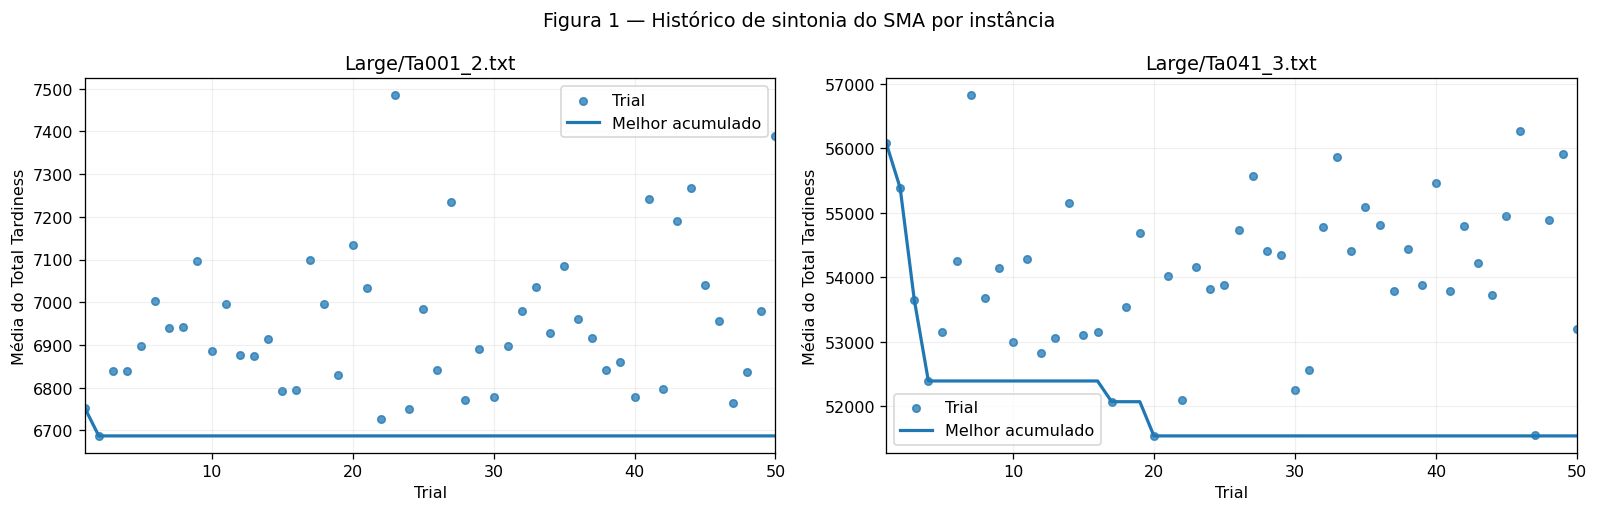

In [5]:
fig,axs=plt.subplots(1,2,figsize=(14,4.5))
for ax,(nome,study) in zip(axs,ESTUDOS.items()):
    vals=np.array([t.value for t in study.trials],dtype=float)
    ax.scatter(np.arange(1,len(vals)+1),vals,s=22,alpha=.75,label='Trial')
    ax.plot(np.arange(1,len(vals)+1),np.minimum.accumulate(vals),lw=2,label='Melhor acumulado')
    ax.set(title=nome, xlabel='Trial',ylabel='Média do Total Tardiness',xlim=(1,len(vals)))
    ax.legend()
fig.suptitle('Figura 1 — Histórico de sintonia do SMA por instância')
fig.tight_layout();display(fig);fig.savefig(OUT/'01_optuna_historico.png',bbox_inches='tight');plt.close(fig)

### 4.2. Importância dos hiperparâmetros

O gráfico de importância estima quais parâmetros estão mais associados às diferenças de score observadas entre as trials. É uma medida **relativa ao espaço de busca e às amostras avaliadas**, não uma afirmação causal sobre o funcionamento do SMA.

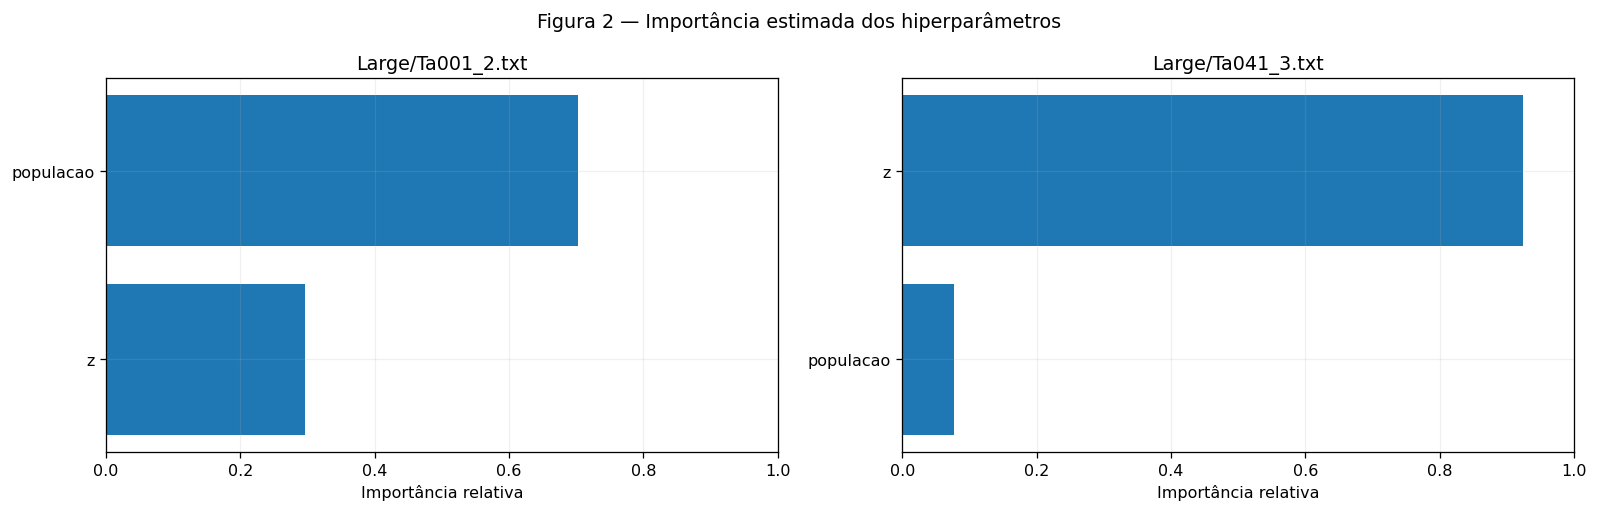

In [6]:
from optuna.importance import get_param_importances
fig,axs=plt.subplots(1,2,figsize=(14,4.5))
for ax,(nome,study) in zip(axs,ESTUDOS.items()):
    try:
        imp=get_param_importances(study)
        ax.barh(list(imp)[::-1],list(imp.values())[::-1]);ax.set_xlim(0,1)
    except Exception as ex:
        ax.text(.5,.5,f'Amostra insuficiente: {type(ex).__name__}',ha='center',va='center',transform=ax.transAxes)
    ax.set(title=nome,xlabel='Importância relativa')
fig.suptitle('Figura 2 — Importância estimada dos hiperparâmetros')
fig.tight_layout();display(fig);fig.savefig(OUT/'02_optuna_importancia.png',bbox_inches='tight');plt.close(fig)

## 5. Amostragem e montagem do dataset supervisionado

São utilizadas duas fontes de soluções:

**LHS:** vetores de Random Keys produzidos por Latin Hypercube Sampling e decodificados em permutações.

**SMA tunado:** candidatos registrados durante execuções com sementes diferentes das utilizadas na sintonia. O fitness de cada um é calculado pelo avaliador exato.

A proporção desejada é 70% LHS e 30% SMA, mas a proporção **efetiva** será informada após a remoção de duplicatas. Se o SMA não oferecer permutações distintas suficientes, o notebook completa a quantidade com LHS, sem fabricar registros atribuídos ao SMA. A meta de permutações únicas será respeitada ou uma exceção identificará que a coleta foi insuficiente.

In [7]:
def dados_instancia(nome,eng,params,alvo):
    inicio=time.perf_counter(); rng=np.random.default_rng(900+eng.n_jobs)
    meta_sma=int(round(alvo*CONFIG['frac_sma']))
    usados=set(); linhas=[]; contagem={'LHS':0,'SMA':0}
    def adicionar(perm,fit,origem):
        chave=tuple(map(int,perm))
        if chave in usados: return False
        usados.add(chave);linhas.append((np.array(perm,dtype=np.int16),float(fit),origem))
        contagem[origem]+=1
        return True
    # Sementes 2000+ não coincidem com as sementes de sintonia e validação do solver.
    visitas=0; tentativas_sma=0
    for rodada in range(CONFIG['max_rodadas_coleta']):
        if contagem['SMA']>=meta_sma: break
        registros=[]
        executar_sma(eng,params,2000+rodada,CONFIG['cfo_coleta'],coletor=registros)
        visitas+=len(registros);tentativas_sma+=1
        for perm,fit,seed,etapa in registros:
            if contagem['SMA']>=meta_sma: break
            adicionar(perm,fit,'SMA')
    # Completar com LHS, verificando a permutação e o fitness reais.
    batches=0
    while len(linhas)<alvo and batches<100:
        faltam=alvo-len(linhas)
        lhc=qmc.LatinHypercube(d=eng.n_jobs,seed=30000+eng.n_jobs+batches)
        keys=lhc.random(n=min(max(300,faltam*2),20000))
        for perm in np.argsort(keys,axis=1):
            if len(linhas)>=alvo: break
            chave=tuple(map(int,perm))
            if chave not in usados:
                adicionar(perm,eng.evaluate_with_permutation(perm),'LHS')
        batches+=1
    if len(linhas)<alvo: raise RuntimeError('Não foi possível atingir a meta de amostras únicas')
    rng.shuffle(linhas)
    perms=np.stack([v[0] for v in linhas]); targets=np.array([v[1] for v in linhas])
    fontes=np.array([v[2] for v in linhas])
    infos={'instancia':nome,'amostras':len(perms),'lhs':contagem['LHS'],
           'sma':contagem['SMA'],'proporcao_sma':contagem['SMA']/len(perms),
           'visitas_sma':visitas,'rodadas_sma':tentativas_sma,
           'tempo_coleta_s':time.perf_counter()-inicio}
    return perms,targets,fontes,infos

DATASETS={}; stats=[]
for nome,eng in ENGINES.items():
    perms,targets,origem,info=dados_instancia(nome,eng,PARAMETROS[nome],CONFIG['samples'][nome])
    assert len(np.unique(perms,axis=0))==len(perms)
    DATASETS[nome]=(perms,targets,origem)
    stats.append(info)
    tag=Path(nome).stem
    np.savez_compressed(OUT/f'{tag}_amostras_completas.npz',permutacoes=perms,fitness_real=targets,origem=origem)
    print(f'{nome}: {len(perms):,} amostras únicas; LHS {info["lhs"]:,}; SMA {info["sma"]:,}; tempo {info["tempo_coleta_s"]:.1f} s')
COLETA=pd.DataFrame(stats);display(COLETA.round(3));COLETA.to_csv(OUT/'resumo_coleta.csv',index=False)

Large/Ta001_2.txt: 10,000 amostras únicas; LHS 7,000; SMA 3,000; tempo 2.2 s
Large/Ta041_3.txt: 20,000 amostras únicas; LHS 14,000; SMA 6,000; tempo 11.6 s


,instancia,amostras,lhs,sma,proporcao_sma,visitas_sma,rodadas_sma,tempo_coleta_s
0,Large/Ta001_2.txt,10000,7000,3000,0.3,6000,2,2.186
1,Large/Ta041_3.txt,20000,14000,6000,0.3,9000,3,11.616


### 5.1. Distribuição dos valores de fitness

Os histogramas identificam as regiões da função objetivo representadas por cada fonte de dados. Uma forte concentração das soluções do SMA em atrasos baixos é esperada, mas não deve ser confundida com uma amostragem uniforme do espaço de permutações.

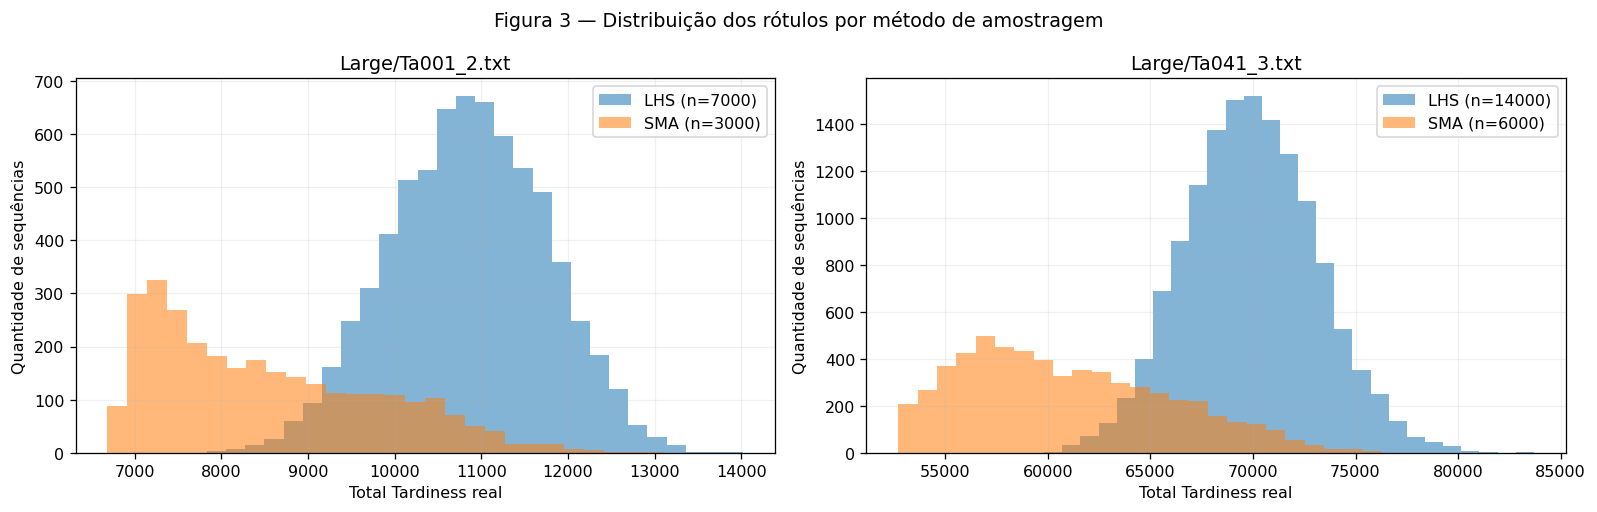

In [8]:
fig,axs=plt.subplots(1,2,figsize=(14,4.5))
for ax,(nome,(perms,y,orig)) in zip(axs,DATASETS.items()):
    for fonte in ['LHS','SMA']:
        valores=y[orig==fonte]
        if len(valores): ax.hist(valores,bins=28,alpha=.55,label=f'{fonte} (n={len(valores)})')
    ax.set(title=nome,xlabel='Total Tardiness real',ylabel='Quantidade de sequências')
    ax.legend()
fig.suptitle('Figura 3 — Distribuição dos rótulos por método de amostragem')
fig.tight_layout();display(fig);fig.savefig(OUT/'03_distribuicao_dados.png',bbox_inches='tight');plt.close(fig)

## 6. Representação, partição dos dados e normalização

Cada permutação é convertida em uma matriz de características ordenadas pelo processamento: tempos nas máquinas e prazo de cada trabalho, conforme sua posição na sequência. A matriz é achatada para produzir uma entrada de dimensão `n_jobs × (n_machines+1)`.

As entradas são normalizadas pela média e desvio-padrão estimados **somente no treino**. O alvo também é padronizado com estatísticas do treino. A divisão treino (70%), validação (15%) e teste (15%) é feita sobre **permutações únicas**, preservando aproximadamente a proporção de fontes na divisão. O teste nunca participa da escolha de épocas nem do ajuste de normalizadores.

In [9]:
def features(engine,perms):
    info=np.column_stack([engine.proc_times,engine.due_dates]).astype(np.float32)
    # Uma linha por posição no sequenciamento, com os atributos do trabalho colocado nela.
    return info[perms].reshape(len(perms),-1)

PARTICOES={}
for nome,(perms,y,orig) in DATASETS.items():
    X=features(ENGINES[nome],perms)
    ids=np.arange(len(y))
    strat=orig if min(np.unique(orig,return_counts=True)[1])>=10 else None
    idx_train,idx_tmp=train_test_split(ids,test_size=.30,random_state=2026,stratify=strat)
    strat_tmp=orig[idx_tmp] if strat is not None else None
    idx_val,idx_test=train_test_split(idx_tmp,test_size=.50,random_state=2027,stratify=strat_tmp)
    scaler_x=StandardScaler().fit(X[idx_train]);scaler_y=StandardScaler().fit(y[idx_train,None])
    PARTICOES[nome]={'X':X,'y':y,'origem':orig,'perms':perms,'train':idx_train,
                     'val':idx_val,'test':idx_test,'scaler_x':scaler_x,'scaler_y':scaler_y}
    assert set(idx_train).isdisjoint(idx_val) and set(idx_train).isdisjoint(idx_test) and set(idx_val).isdisjoint(idx_test)
    print(f'{nome}: treino={len(idx_train)} validação={len(idx_val)} teste={len(idx_test)}; entrada={X.shape[1]}')
    np.savez_compressed(OUT/f'{Path(nome).stem}_divisao.npz',train=idx_train,val=idx_val,test=idx_test)

Large/Ta001_2.txt: treino=7000 validação=1500 teste=1500; entrada=120
Large/Ta041_3.txt: treino=14000 validação=3000 teste=3000; entrada=550


## 7. Treinamento da rede neural MLP

A MLP utiliza três camadas ocultas (128, 64 e 32 unidades) com ReLU e uma saída linear para regressão. O treinamento usa MSE, Adam e early stopping pela menor perda de validação. Os modelos são treinados separadamente para as duas instâncias.

A previsão é uma aproximação do fitness, não uma avaliação exata; todas as soluções finais relatadas na etapa de otimização são confirmadas pela `FlowShopEngine`.

In [10]:
class MLP(nn.Module):
    def __init__(self,entrada):
        super().__init__()
        self.camadas=nn.Sequential(nn.Linear(entrada,128),nn.ReLU(),
                                  nn.Linear(128,64),nn.ReLU(),
                                  nn.Linear(64,32),nn.ReLU(),nn.Linear(32,1))
    def forward(self,x): return self.camadas(x)

def treinar_mlp(nome,dados):
    torch.manual_seed(SEMENTE_GLOBAL)
    sx,sy=dados['scaler_x'],dados['scaler_y']
    X=dados['X'];y=dados['y'];train,val=dados['train'],dados['val']
    xt=torch.from_numpy(sx.transform(X[train]).astype('float32'))
    yt=torch.from_numpy(sy.transform(y[train,None]).astype('float32'))
    xv=torch.from_numpy(sx.transform(X[val]).astype('float32'))
    yv=torch.from_numpy(sy.transform(y[val,None]).astype('float32'))
    dl=DataLoader(TensorDataset(xt,yt),batch_size=CONFIG['batch_size'],shuffle=True)
    model=MLP(X.shape[1]);opt=torch.optim.Adam(model.parameters(),lr=1e-3)
    loss_fn=nn.MSELoss();log=[];best=np.inf;estado=None;sem_melhora=0
    t0=time.perf_counter()
    for epoch in range(CONFIG['epochs']):
        model.train();soma=0.;quant=0
        for xb,yb in dl:
            opt.zero_grad();loss=loss_fn(model(xb),yb);loss.backward();opt.step()
            soma+=float(loss.item())*len(xb);quant+=len(xb)
        model.eval()
        with torch.no_grad(): val_loss=float(loss_fn(model(xv),yv).item())
        log.append((epoch+1,soma/quant,val_loss))
        if val_loss<best-1e-6:
            best=val_loss;sem_melhora=0
            estado={k:v.detach().clone() for k,v in model.state_dict().items()}
        else: sem_melhora+=1
        if sem_melhora>=CONFIG['patience']: break
    model.load_state_dict(estado);model.eval()
    return model,np.asarray(log),time.perf_counter()-t0

MODELOS={};HISTORICOS={};TEMPOS_TREINO={}
for nome,dados in PARTICOES.items():
    model,hist,dur=treinar_mlp(nome,dados)
    MODELOS[nome]=model;HISTORICOS[nome]=hist;TEMPOS_TREINO[nome]=dur
    print(f'{nome}: {len(hist)} épocas; melhor MSE normalizado de validação {hist[:,2].min():.5f}; {dur:.1f} s')
    torch.save(model.state_dict(),OUT/f'{Path(nome).stem}_mlp.pt')
# Os transformadores de atributos e alvo são parte integrante do modelo treinado.
import joblib
for nome,d in PARTICOES.items():
    joblib.dump({'scaler_x':d['scaler_x'],'scaler_y':d['scaler_y']},OUT/f'{Path(nome).stem}_scalers.joblib')


Large/Ta001_2.txt: 35 épocas; melhor MSE normalizado de validação 0.05539; 3.8 s
Large/Ta041_3.txt: 22 épocas; melhor MSE normalizado de validação 0.15435; 4.6 s


### 7.1. Curvas de aprendizado

Uma queda simultânea das perdas de treino e validação indica progresso da regressão. Aumento persistente da perda de validação, enquanto a de treino diminui, sugere sobreajuste. As curvas são mostradas no espaço normalizado do alvo.

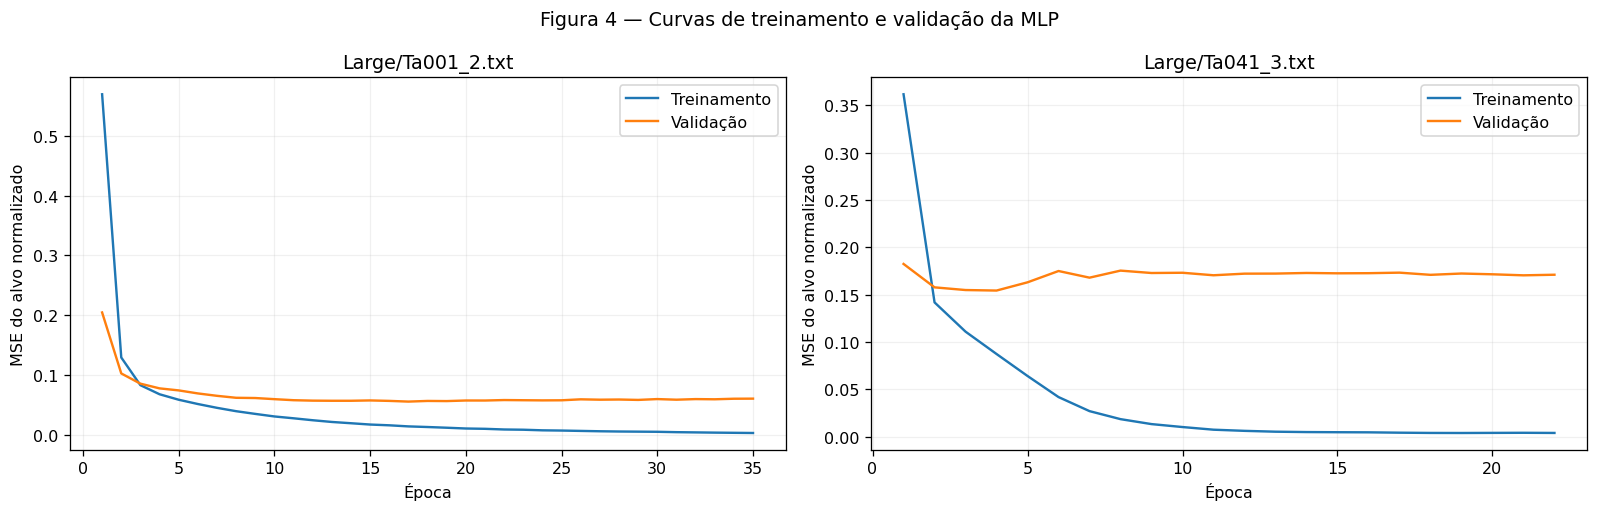

In [11]:
fig,axs=plt.subplots(1,2,figsize=(14,4.5))
for ax,(nome,h) in zip(axs,HISTORICOS.items()):
    ax.plot(h[:,0],h[:,1],label='Treinamento');ax.plot(h[:,0],h[:,2],label='Validação')
    ax.set(title=nome,xlabel='Época',ylabel='MSE do alvo normalizado');ax.legend()
fig.suptitle('Figura 4 — Curvas de treinamento e validação da MLP')
fig.tight_layout();display(fig);fig.savefig(OUT/'04_curvas_treino.png',bbox_inches='tight');plt.close(fig)

## 8. Avaliação da regressão em permutações não vistas

As métricas MSE e RMSE são calculadas na escala original do Total Tardiness, juntamente com MAE e R². A correlação de Spearman verifica se o modelo preserva aproximadamente a **ordenação relativa** das soluções. Também é registrada a taxa de acerto na escolha da melhor solução dentro de pares aleatórios; isso é particularmente importante para utilização do surrogate na busca.

In [12]:
def prever_lote(nome,perms):
    eng=ENGINES[nome];d=PARTICOES[nome];modelo=MODELOS[nome]
    if len(perms)==0:return np.array([])
    xx=features(eng,np.asarray(perms))
    xx=d['scaler_x'].transform(xx).astype('float32')
    saidas=[]
    with torch.no_grad():
        for bloco in np.array_split(xx,max(1,int(np.ceil(len(xx)/512)))):
            pred=modelo(torch.from_numpy(bloco)).numpy()
            saidas.append(pred)
    return d['scaler_y'].inverse_transform(np.vstack(saidas)).ravel()

PREVISOES={};metricas=[]
for nome,d in PARTICOES.items():
    ix=d['test'];real=d['y'][ix];prev=prever_lote(nome,d['perms'][ix]);PREVISOES[nome]=(real,prev)
    rng=np.random.default_rng(654);a=rng.integers(0,len(real),size=2000);b=rng.integers(0,len(real),size=2000)
    valid=(real[a]!=real[b]);pares=np.mean((prev[a][valid]<prev[b][valid])==(real[a][valid]<real[b][valid])) if valid.any() else float('nan')
    rho=spearmanr(real,prev).statistic
    metricas.append({'instancia':nome,'MSE':mean_squared_error(real,prev),
                     'RMSE':np.sqrt(mean_squared_error(real,prev)),
                     'MAE':mean_absolute_error(real,prev),'R2':r2_score(real,prev),
                     'Spearman':rho,'acerto_pares':pares,'n_teste':len(ix)})
METRICAS=pd.DataFrame(metricas);display(METRICAS.round(4));METRICAS.to_csv(OUT/'metricas_regressao.csv',index=False)

,instancia,MSE,RMSE,MAE,R2,Spearman,acerto_pares,n_teste
0,Large/Ta001_2.txt,1.311018e+05,362.0799,280.5668,0.9426,0.9519,0.9109,1500
1,Large/Ta041_3.txt,4.742132e+06,2177.6436,1695.6457,0.8523,0.8590,0.8559,3000


### 8.1. Valor real versus previsto

A linha tracejada representa a previsão perfeita. Dispersão concentrada perto da diagonal indica boa concordância. Desvios sistemáticos, sobretudo entre as soluções de menor atraso, podem afetar a seleção de candidatos pelo SMA.

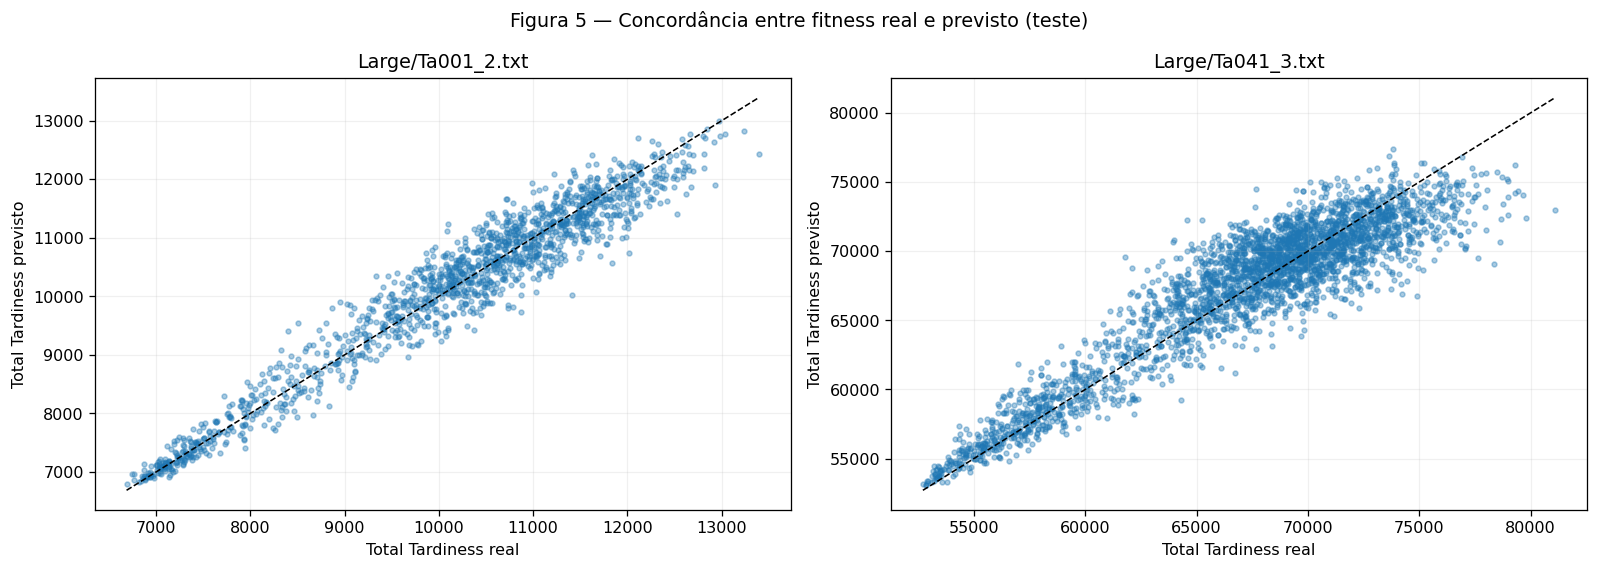

In [13]:
fig,axs=plt.subplots(1,2,figsize=(14,5))
for ax,(nome,(y,p)) in zip(axs,PREVISOES.items()):
    ax.scatter(y,p,s=9,alpha=.38);lo=min(y.min(),p.min());hi=max(y.max(),p.max())
    ax.plot([lo,hi],[lo,hi],'--',color='black',lw=1)
    ax.set(title=nome,xlabel='Total Tardiness real',ylabel='Total Tardiness previsto')
fig.suptitle('Figura 5 — Concordância entre fitness real e previsto (teste)')
fig.tight_layout();display(fig);fig.savefig(OUT/'05_real_vs_previsto.png',bbox_inches='tight');plt.close(fig)

### 8.2. Distribuição dos erros e erro nas melhores soluções

O resíduo é calculado como `previsto − real`. Resíduos positivos correspondem a superestimação. O gráfico por faixa compara o erro absoluto nas soluções de menor atraso com o restante da distribuição de teste; diferenças altas nessa região merecem atenção mesmo quando o R² global é satisfatório.

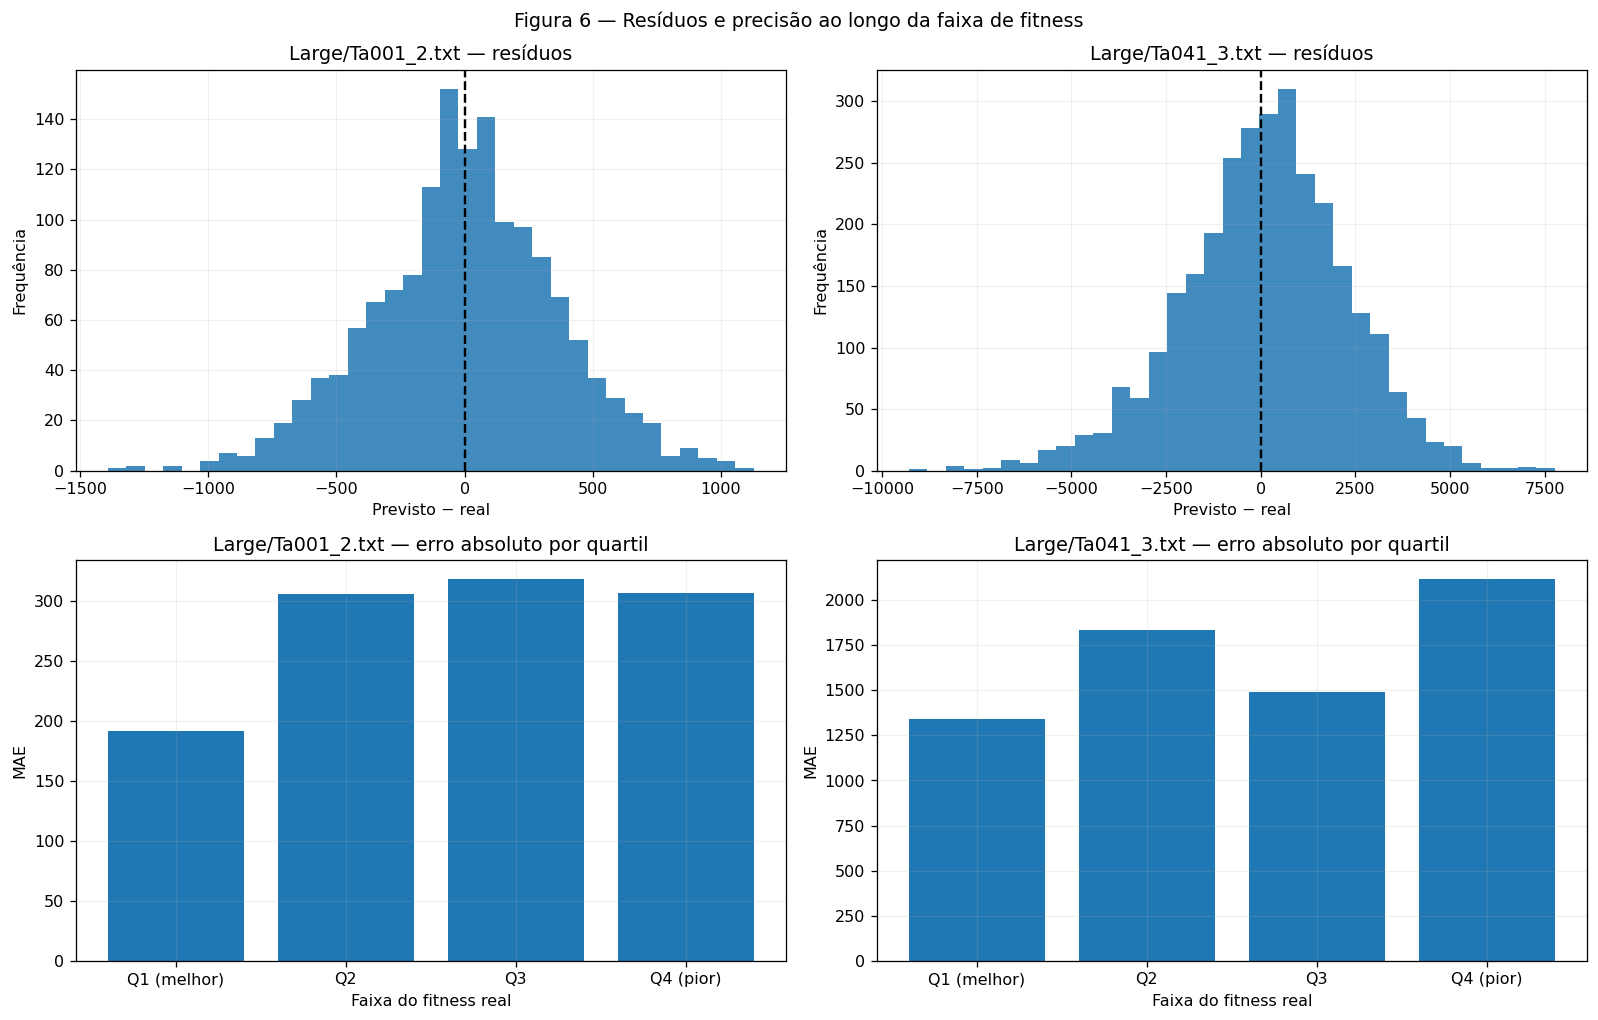

In [14]:
fig,axs=plt.subplots(2,2,figsize=(14,9))
for col,(nome,(y,p)) in enumerate(PREVISOES.items()):
    err=p-y
    axs[0,col].hist(err,bins=35,alpha=.85);axs[0,col].axvline(0,ls='--',color='black')
    axs[0,col].set(title=f'{nome} — resíduos',xlabel='Previsto − real',ylabel='Frequência')
    cuts=np.quantile(y,[0,.25,.50,.75,1])
    categorias=np.clip(np.searchsorted(cuts[1:-1],y,side='right'),0,3)
    vals=[np.abs(err[categorias==i]).mean() for i in range(4)]
    axs[1,col].bar(['Q1 (melhor)','Q2','Q3','Q4 (pior)'],vals)
    axs[1,col].set(title=f'{nome} — erro absoluto por quartil',ylabel='MAE',xlabel='Faixa do fitness real')
fig.suptitle('Figura 6 — Resíduos e precisão ao longo da faixa de fitness')
fig.tight_layout();display(fig);fig.savefig(OUT/'06_analise_residuos.png',bbox_inches='tight');plt.close(fig)

## 9. Tempo computacional: avaliação exata versus MLP

A comparação é feita para o mesmo conjunto de permutações. São informados dois cenários: **avaliação real sequencial**, correspondente à chamada disponível na `FlowShopEngine`, e **inferência em lote**, favorecida pela vetorização da rede neural. O tempo de geração dos dados e de treino não é omitido: ele será mostrado à parte para avaliar o custo total da abordagem.

Uma diferença de tempo na predição isolada não garante que o solver completo seja mais rápido.

In [15]:
tempos=[]
for nome,eng in ENGINES.items():
    d=PARTICOES[nome];perms=d['perms'][d['test'][:min(1000,len(d['test']))]]
    _=prever_lote(nome,perms[:min(64,len(perms))]) # aquecimento
    t0=time.perf_counter()
    exato=np.array([eng.evaluate_with_permutation(p) for p in perms])
    t_real=time.perf_counter()-t0
    t0=time.perf_counter();prev=prever_lote(nome,perms)
    t_rede=time.perf_counter()-t0
    tempos.append({'instancia':nome,'n_avaliacoes':len(perms),
                   'tempo_real_s':t_real,'tempo_rede_lote_s':t_rede,
                   'aceleracao_inferencia':t_real/max(t_rede,1e-12),
                   'coleta_s':float(COLETA.set_index('instancia').loc[nome,'tempo_coleta_s']),
                   'treino_s':TEMPOS_TREINO[nome]})
TEMPOS=pd.DataFrame(tempos);display(TEMPOS.round(4));TEMPOS.to_csv(OUT/'tempos_avaliacao.csv',index=False)

,instancia,n_avaliacoes,tempo_real_s,tempo_rede_lote_s,aceleracao_inferencia,coleta_s,treino_s
0,Large/Ta001_2.txt,1000,0.0908,0.0028,32.1860,2.1862,3.8425
1,Large/Ta041_3.txt,1000,0.3615,0.0054,66.6394,11.6156,4.6270


## 10. Integração ao SMA: seleção assistida pela MLP

Na versão assistida, cada geração produz candidatos a partir dos operadores do SMA; a rede prevê seus fitness em lote. Somente a fração com menor valor previsto passa pela avaliação exata. **O melhor valor final é sempre confirmado pela função real.** Os candidatos não verificados recebem o valor previsto apenas para orientar a atualização seguinte.

O número de avaliações exatas da função objetivo é igualado entre o SMA convencional e o assistido. Como a versão assistida avalia mais candidatos virtualmente, também comparamos o tempo real de execução. Esse experimento não desconta o custo anterior de coleta e treino, que aparece em seção própria.

In [16]:

def executar_sma_assistido(nome,params,seed,budget,frac=.4):
    eng=ENGINES[nome]
    pop=int(params['populacao'])
    def escolher(X,restantes):
        previsto=prever_lote(nome,np.argsort(X,axis=1,kind='stable'))
        q=min(max(1,int(np.ceil(frac*pop))),restantes)
        indices=np.argsort(previsto,kind='stable')[:q]
        return previsto,indices
    r=sma_otimizar(lambda x: eng.evaluate(x),eng.n_jobs,populacao=pop,
                   avaliacoes=budget,seed=seed,z=float(params['z']),seletor=escolher)
    return {'fitness':r['fitness'], 'permutacao':eng.bucket_sort_decode(r['melhor_posicao']),
            'historico':r['historico'],'cfo':r['cfo']}

for nome,eng in ENGINES.items():
    test_budget=max(int(PARAMETROS[nome]['populacao'])+5,min(120,CONFIG['cfo_comparacao']))
    r=executar_sma_assistido(nome,PARAMETROS[nome],12345,test_budget,CONFIG['frac_selecao'])
    assert r['cfo']==test_budget
    assert np.array_equal(np.sort(r['permutacao']),np.arange(eng.n_jobs))
print('Verificação de validade das soluções assistidas: OK')


Verificação de validade das soluções assistidas: OK


### 10.1. Comparação experimental entre os dois modos

As duas versões usam a mesma configuração tunada e as mesmas sementes. São registrados fitness final, quantidade de avaliações exatas, tempo total e histórico de convergência. O orçamento de avaliações não inclui o custo de geração dos rótulos e treinamento da rede, informado separadamente em `TEMPOS`. A comparação é ilustrativa da integração por instância, e não constitui evidência de generalização para instâncias não utilizadas no desenvolvimento.

In [17]:
registros=[];CURVAS={}
for nome,eng in ENGINES.items():
    for seed in CONFIG['seeds_comparacao']:
        for metodo in ['SMA exato','SMA + MLP']:
            t0=time.perf_counter()
            if metodo=='SMA exato':
                r=executar_sma(eng,PARAMETROS[nome],seed,CONFIG['cfo_comparacao'])
            else:
                r=executar_sma_assistido(nome,PARAMETROS[nome],seed,CONFIG['cfo_comparacao'],CONFIG['frac_selecao'])
            dur=time.perf_counter()-t0
            assert r['cfo']==CONFIG['cfo_comparacao']
            registros.append({'instancia':nome,'semente':seed,'metodo':metodo,
                              'fitness':r['fitness'],'cfo':r['cfo'],'segundos':dur})
            CURVAS[(nome,seed,metodo)]=r['historico']
RESULTADOS=pd.DataFrame(registros)
RESUMO=RESULTADOS.groupby(['instancia','metodo'],as_index=False).agg(
    media_fitness=('fitness','mean'),std_fitness=('fitness','std'),melhor=('fitness','min'),
    pior=('fitness','max'),media_tempo_s=('segundos','mean'),avaliacoes=('cfo','mean'))
display(RESUMO.round(3));RESULTADOS.to_csv(OUT/'execucoes_sma_surrogate.csv',index=False)
RESUMO.to_csv(OUT/'resumo_sma_surrogate.csv',index=False)

,instancia,metodo,media_fitness,std_fitness,melhor,pior,media_tempo_s,avaliacoes
0,Large/Ta001_2.txt,SMA + MLP,6821.6,205.768,6621.0,7166.0,1.433,3000.0
1,Large/Ta001_2.txt,SMA exato,6797.4,74.026,6674.0,6855.0,0.682,3000.0
2,Large/Ta041_3.txt,SMA + MLP,51260.4,309.733,50877.0,51603.0,3.924,3000.0
3,Large/Ta041_3.txt,SMA exato,54165.6,1638.974,51715.0,55328.0,2.055,3000.0


### 10.2. Comparação de qualidade e custo

A comparação distingue dois objetivos: **qualidade final** (menor Total Tardiness) e **custo operacional** (menor tempo de execução). Como os métodos utilizam o mesmo número de avaliações reais, qualquer ganho da versão assistida precisa ser interpretado juntamente com seu tempo de predição e a qualidade de seleção dos candidatos.

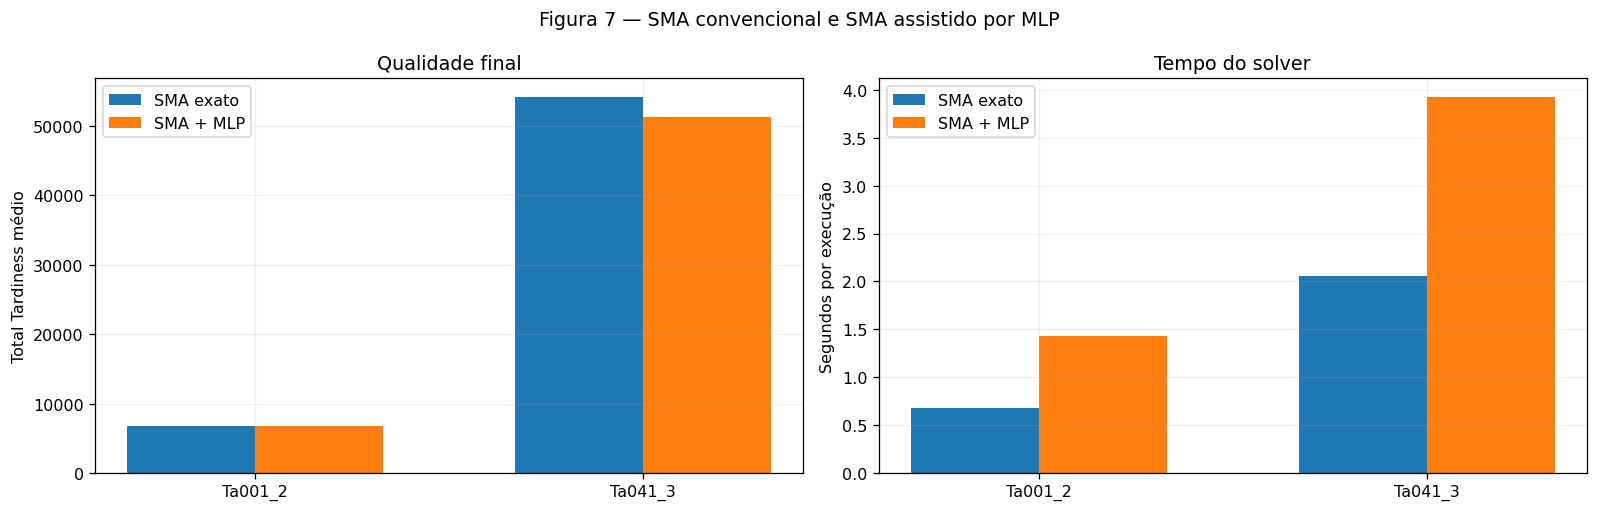

In [18]:
fig,axs=plt.subplots(1,2,figsize=(14,4.5))
metodos=['SMA exato','SMA + MLP']; x=np.arange(len(INSTANCIAS));larg=.33
for k,met in enumerate(metodos):
    dados=RESUMO[RESUMO.metodo==met].set_index('instancia').loc[INSTANCIAS]
    axs[0].bar(x+(k-.5)*larg,dados.media_fitness,width=larg,label=met)
    axs[1].bar(x+(k-.5)*larg,dados.media_tempo_s,width=larg,label=met)
for ax in axs:
    ax.set_xticks(x,[Path(s).stem for s in INSTANCIAS]);ax.legend()
axs[0].set(title='Qualidade final',ylabel='Total Tardiness médio')
axs[1].set(title='Tempo do solver',ylabel='Segundos por execução')
fig.suptitle('Figura 7 — SMA convencional e SMA assistido por MLP')
fig.tight_layout();display(fig);fig.savefig(OUT/'07_comparacao_solver.png',bbox_inches='tight');plt.close(fig)

### 10.3. Curvas de convergência

O eixo horizontal contém o número de avaliações **reais** acumuladas, não o número de predições da rede. Cada curva mostra o melhor fitness confirmado até aquele ponto. As curvas apresentadas correspondem à primeira semente da comparação, evitando misturar trajetórias de execuções diferentes.

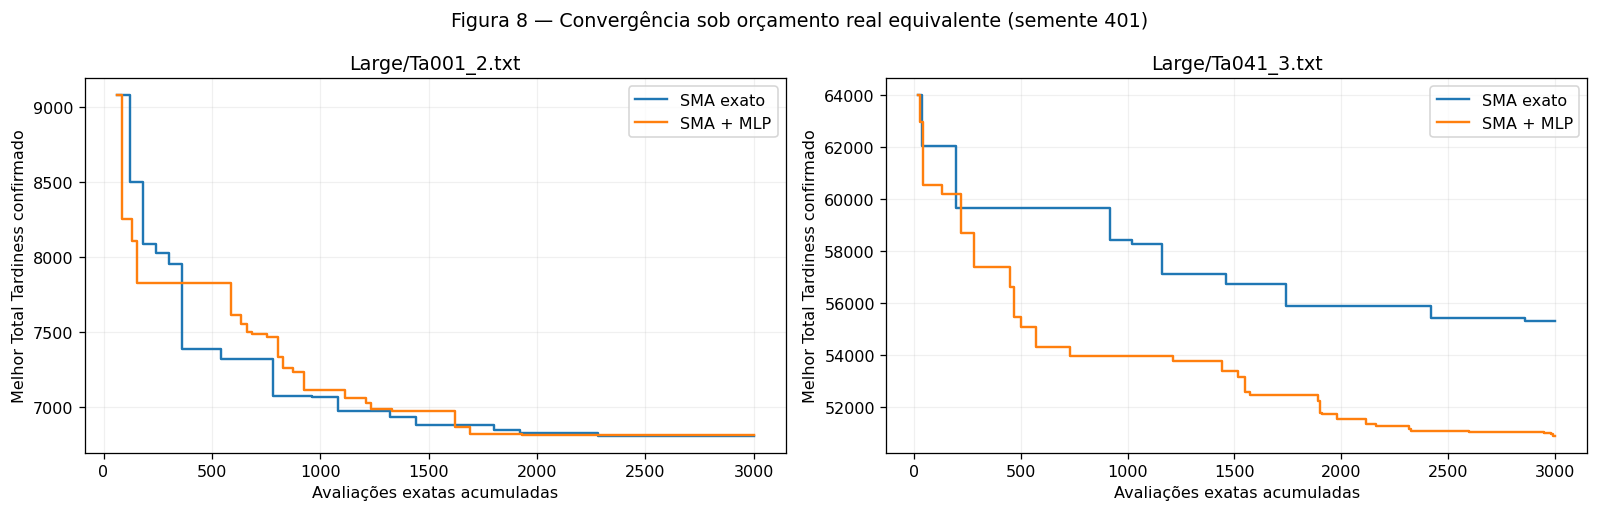

In [19]:
fig,axs=plt.subplots(1,2,figsize=(14,4.5))
seed=CONFIG['seeds_comparacao'][0]
for ax,nome in zip(axs,INSTANCIAS):
    for metodo in ['SMA exato','SMA + MLP']:
        h=CURVAS[(nome,seed,metodo)]
        ax.step(h[:,0],h[:,1],where='post',label=metodo)
    ax.set(title=nome,xlabel='Avaliações exatas acumuladas',ylabel='Melhor Total Tardiness confirmado')
    ax.legend()
fig.suptitle(f'Figura 8 — Convergência sob orçamento real equivalente (semente {seed})')
fig.tight_layout();display(fig);fig.savefig(OUT/'08_convergencia_solver.png',bbox_inches='tight');plt.close(fig)

## 11. Discussão dos resultados

Esta seção utiliza os resultados calculados para comentar a confiabilidade da MLP, a eficiência da inferência e o impacto observado no SMA. A melhora ou piora do solver assistido **não é pressuposta**. Resultados de regressão e resultados de otimização são analisados separadamente.

In [20]:
for nome in INSTANCIAS:
    reg=METRICAS.set_index('instancia').loc[nome]
    t=TEMPOS.set_index('instancia').loc[nome]
    s=RESUMO[RESUMO.instancia==nome].set_index('metodo')
    a=s.loc['SMA exato'];b=s.loc['SMA + MLP']
    ganho=(a.media_fitness-b.media_fitness)/max(1e-9,a.media_fitness)*100
    tempo_rel=(b.media_tempo_s/a.media_tempo_s-1)*100
    print(f'\nINSTÂNCIA {nome}')
    print(f'1. Regressão: RMSE={reg.RMSE:,.2f}; MAE={reg.MAE:,.2f}; R²={reg.R2:.4f}; Spearman={reg.Spearman:.4f}.')
    print(f'   Acerto na comparação de pares: {reg.acerto_pares*100:.1f}%.')
    print(f'2. Inferência: {t.tempo_rede_lote_s:.4f} s para {int(t.n_avaliacoes)} sequências, '
          f'contra {t.tempo_real_s:.4f} s da avaliação exata sequencial; razão {t.aceleracao_inferencia:.2f}x.')
    print(f'   Geração dos dados: {t.coleta_s:.1f} s; treinamento: {t.treino_s:.1f} s.')
    print(f'3. Solver: SMA exato={a.media_fitness:,.2f}; SMA+MLP={b.media_fitness:,.2f}; '
          f'ganho de qualidade do assistido={ganho:+.2f}%.')
    print(f'   Tempo médio do solver: {a.media_tempo_s:.3f} s (exato) e '
          f'{b.media_tempo_s:.3f} s (assistido), variação={tempo_rel:+.1f}%.')
    if ganho>0: print('   O assistido obteve menor atraso médio nas sementes avaliadas.')
    elif ganho<0: print('   O assistido obteve maior atraso médio nas sementes avaliadas.')
    else: print('   Os métodos apresentaram o mesmo atraso médio nas sementes avaliadas.')
    if reg.R2<0: print('   Atenção: a regressão ficou inferior à previsão constante pela média no conjunto de teste.')
    if reg.acerto_pares<.6: print('   Atenção: a ordenação de soluções pelo surrogate mostrou baixa confiabilidade.')
print('\nLIMITAÇÕES: modelos específicos por instância; custo de treinamento separado do tempo do solver; '
      'mesmo orçamento de avaliações exatas, mas quantidade de propostas diferente entre variantes. '
      'A avaliação da MLP em novas permutações não demonstra generalização para outras instâncias.')


INSTÂNCIA Large/Ta001_2.txt
1. Regressão: RMSE=362.08; MAE=280.57; R²=0.9426; Spearman=0.9519.
   Acerto na comparação de pares: 91.1%.
2. Inferência: 0.0028 s para 1000 sequências, contra 0.0908 s da avaliação exata sequencial; razão 32.19x.
   Geração dos dados: 2.2 s; treinamento: 3.8 s.
3. Solver: SMA exato=6,797.40; SMA+MLP=6,821.60; ganho de qualidade do assistido=-0.36%.
   Tempo médio do solver: 0.682 s (exato) e 1.433 s (assistido), variação=+110.2%.
   O assistido obteve maior atraso médio nas sementes avaliadas.

INSTÂNCIA Large/Ta041_3.txt
1. Regressão: RMSE=2,177.64; MAE=1,695.65; R²=0.8523; Spearman=0.8590.
   Acerto na comparação de pares: 85.6%.
2. Inferência: 0.0054 s para 1000 sequências, contra 0.3615 s da avaliação exata sequencial; razão 66.64x.
   Geração dos dados: 11.6 s; treinamento: 4.6 s.
3. Solver: SMA exato=54,165.60; SMA+MLP=51,260.40; ganho de qualidade do assistido=+5.36%.
   Tempo médio do solver: 2.055 s (exato) e 3.924 s (assistido), variação=+90.9%.

## 12. Reprodutibilidade e arquivos gerados

O diretório de saída contém os hiperparâmetros selecionados, histórico de trials, permutações e fitness reais, índices das divisões, pesos das MLPs, métricas de regressão, tempos, resultados do SMA convencional e assistido, além dos gráficos apresentados ao longo do relatório.

O treinamento é reprodutível a partir das sementes declaradas, sujeito às pequenas diferenças numéricas entre versões das bibliotecas. Os rótulos de treinamento são sempre calculados pelo avaliador exato. O custo da sintonia e de geração das amostras é parte do investimento de preparação do surrogate, não deve ser omitido em análises de desempenho global.

In [21]:
manifesto={'titulo':'Semana 4 — Treinamento e integração de um modelo surrogate',
           'formulacao':'Permutation Flow Shop (PFS), Total Tardiness',
           'instancias':INSTANCIAS,'configuracao':CONFIG,
           'parametros_por_instancia':PARAMETROS,
           'nota':'Resultados e gráficos derivados da execução deste notebook. Não incluem dados fictícios.'}
with open(OUT/'manifesto_experimento.json','w',encoding='utf-8') as f:
    json.dump(manifesto,f,indent=2,ensure_ascii=False)
print('Arquivos salvos em:',OUT)
for p in sorted(OUT.iterdir()): print(' -',p.name)

Arquivos salvos em: /kaggle/working/semana4_surrogate
 - 01_optuna_historico.png
 - 02_optuna_importancia.png
 - 03_distribuicao_dados.png
 - 04_curvas_treino.png
 - 05_real_vs_previsto.png
 - 06_analise_residuos.png
 - 07_comparacao_solver.png
 - 08_convergencia_solver.png
 - Ta001_2_amostras_completas.npz
 - Ta001_2_divisao.npz
 - Ta001_2_mlp.pt
 - Ta001_2_scalers.joblib
 - Ta041_3_amostras_completas.npz
 - Ta041_3_divisao.npz
 - Ta041_3_mlp.pt
 - Ta041_3_scalers.joblib
 - execucoes_sma_surrogate.csv
 - manifesto_experimento.json
 - metricas_regressao.csv
 - optuna_resumo.csv
 - optuna_trials.csv
 - parametros_sma_por_instancia.json
 - resumo_coleta.csv
 - resumo_sma_surrogate.csv
 - tempos_avaliacao.csv
